# EA2 - Modelos de Predicción(Regresion Lineal)

## Integrantes

Natalia Jadith Castro Ospino

Oscar Luis Marquez Arrieta

# Preparar e Importar la clase de carga

In [1]:

import sys
from pathlib import Path
import pandas as pd

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "clases").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from clases.hf_loader import HFDatasetLoader

# Configurar DataSet

In [2]:

loader = HFDatasetLoader(
    dataset_name="MoazIrfan/student-score-dataset",
    split="train",
    filename="datos/MoazIrfan/student-score-dataset.csv",
)

# Descargar Dataset y crear DataFrame

In [3]:

df = loader.load()
df.head(3)

README.md:   0%|          | 0.00/24.0 [00:00<?, ?B/s]

Expanded_data.csv:   0%|          | 0.00/2.91M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/30641 [00:00<?, ? examples/s]

,Unnamed: 0,Gender,EthnicGroup,ParentEduc,LunchType,TestPrep,ParentMaritalStatus,PracticeSport,IsFirstChild,NrSiblings,TransportMeans,WklyStudyHours,MathScore,ReadingScore,WritingScore
0,0,female,NaN,bachelor's degree,standard,none,married,regularly,yes,3.0,school_bus,< 5,71,71,74
1,1,female,group C,some college,standard,NaN,married,sometimes,yes,0.0,NaN,5 - 10,69,90,88
2,2,female,group B,master's degree,standard,none,single,sometimes,yes,4.0,school_bus,< 5,87,93,91


# Revisar Dataset

In [4]:


import pandas as pd
from datasets import load_dataset

# Cargar el dataset desde Hugging Face
dataset = load_dataset("MoazIrfan/student-score-dataset")

# Convertir los datos a un DataFrame
df = dataset["train"].to_pandas()

# Mostrar información general
print("Tamaño original:", df.shape)

print("\nPrimeras cinco filas:")
display(df.head())

# Revisar los valores nulos
print("\nValores nulos por columna:")
print(df.isnull().sum())

# Revisar los registros duplicados
print("\nFilas duplicadas:", df.duplicated().sum())

# Revisar los tipos de datos
print("\nTipos de datos:")
print(df.dtypes)



Tamaño original: (30641, 15)

Primeras cinco filas:


,Unnamed: 0,Gender,EthnicGroup,ParentEduc,LunchType,TestPrep,ParentMaritalStatus,PracticeSport,IsFirstChild,NrSiblings,TransportMeans,WklyStudyHours,MathScore,ReadingScore,WritingScore
0,0,female,NaN,bachelor's degree,standard,none,married,regularly,yes,3.0,school_bus,< 5,71,71,74
1,1,female,group C,some college,standard,NaN,married,sometimes,yes,0.0,NaN,5 - 10,69,90,88
2,2,female,group B,master's degree,standard,none,single,sometimes,yes,4.0,school_bus,< 5,87,93,91
3,3,male,group A,associate's degree,free/reduced,none,married,never,no,1.0,NaN,5 - 10,45,56,42
4,4,male,group C,some college,standard,none,married,sometimes,yes,0.0,school_bus,5 - 10,76,78,75



Valores nulos por columna:
Unnamed: 0                0
Gender                    0
EthnicGroup            1840
ParentEduc             1845
LunchType                 0
TestPrep               1830
ParentMaritalStatus    1190
PracticeSport           631
IsFirstChild            904
NrSiblings             1572
TransportMeans         3134
WklyStudyHours          955
MathScore                 0
ReadingScore              0
WritingScore              0
dtype: int64

Filas duplicadas: 0

Tipos de datos:
Unnamed: 0               int64
Gender                     str
EthnicGroup                str
ParentEduc                 str
LunchType                  str
TestPrep                   str
ParentMaritalStatus        str
PracticeSport              str
IsFirstChild               str
NrSiblings             float64
TransportMeans             str
WklyStudyHours             str
MathScore                int64
ReadingScore             int64
WritingScore             int64
dtype: object


# Pregunta Orientadora

¿Podemos predecir la nota de matematica de un estudiante a partir de sus notas de lectura y escritura?

# Limpieza y seleccion de variables

In [5]:
df["MathScore"].head()

0    71
1    69
2    87
3    45
4    76
Name: MathScore, dtype: int64

In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import numpy as np

X, y = df[["ReadingScore", "WritingScore"]], df["MathScore"] # preparar datos

modelo = LinearRegression() # inicializar modelo

X_train, X_test, y_train, y_test = train_test_split( # dividir_datos
    X, y, test_size=0.2, random_state=42
)

modelo.fit(X_train, y_train) # entrenamiento

predicciones = modelo.predict(X_test) # prediccion

w = modelo.coef_[0]
b = modelo.intercept_

print(f"MAE: {mean_absolute_error(y_test, predicciones):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, predicciones)):.2f}")
print(f"R2: {r2_score(y_test, predicciones):.2f}")
print(f"w: {w}")
print(f"b: {b:.2f}")

MAE: 7.13
RMSE: 8.71
R2: 0.67
w: 0.5523832738208165
b: 7.61


In [7]:

print("Coeficiente ReadingScore:", modelo.coef_[0])
print("Coeficiente WritingScore:", modelo.coef_[1])
print("Intercepto:", modelo.intercept_)


Coeficiente ReadingScore: 0.5523832738208165
Coeficiente WritingScore: 0.3010194901817598
Intercepto: 7.612481866136285


# Graficos

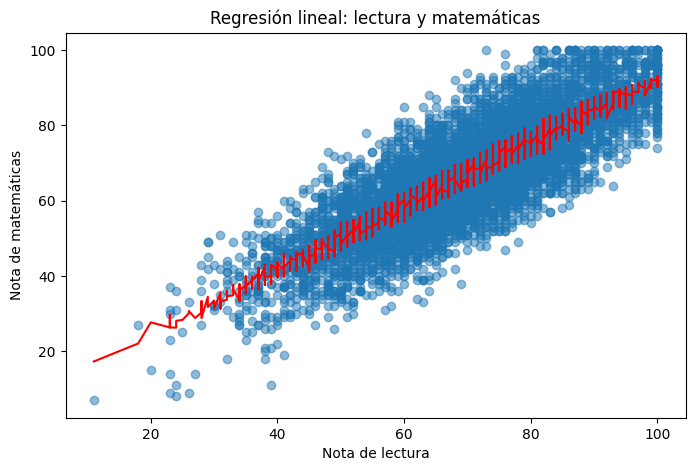

In [8]:

import matplotlib.pyplot as plt
from IPython.display import display

# Obtener los datos de prueba
x_test = X_test["ReadingScore"].to_numpy()
y_test_array = y_test.to_numpy()

# Ordenar los datos para dibujar la línea
orden = x_test.argsort()

# Crear el gráfico
fig, ax = plt.subplots(figsize=(8, 5))

# Mostrar las notas reales de matemáticas
ax.scatter(
    x_test,
    y_test_array,
    alpha=0.5,
)

# Mostrar las predicciones del modelo
ax.plot(
    x_test[orden],
    predicciones[orden],
    color="red",
)

# Etiquetas del gráfico
ax.set_xlabel("Nota de lectura")
ax.set_ylabel("Nota de matemáticas")
ax.set_title("Regresión lineal: lectura y matemáticas")

display(fig)
plt.close(fig)


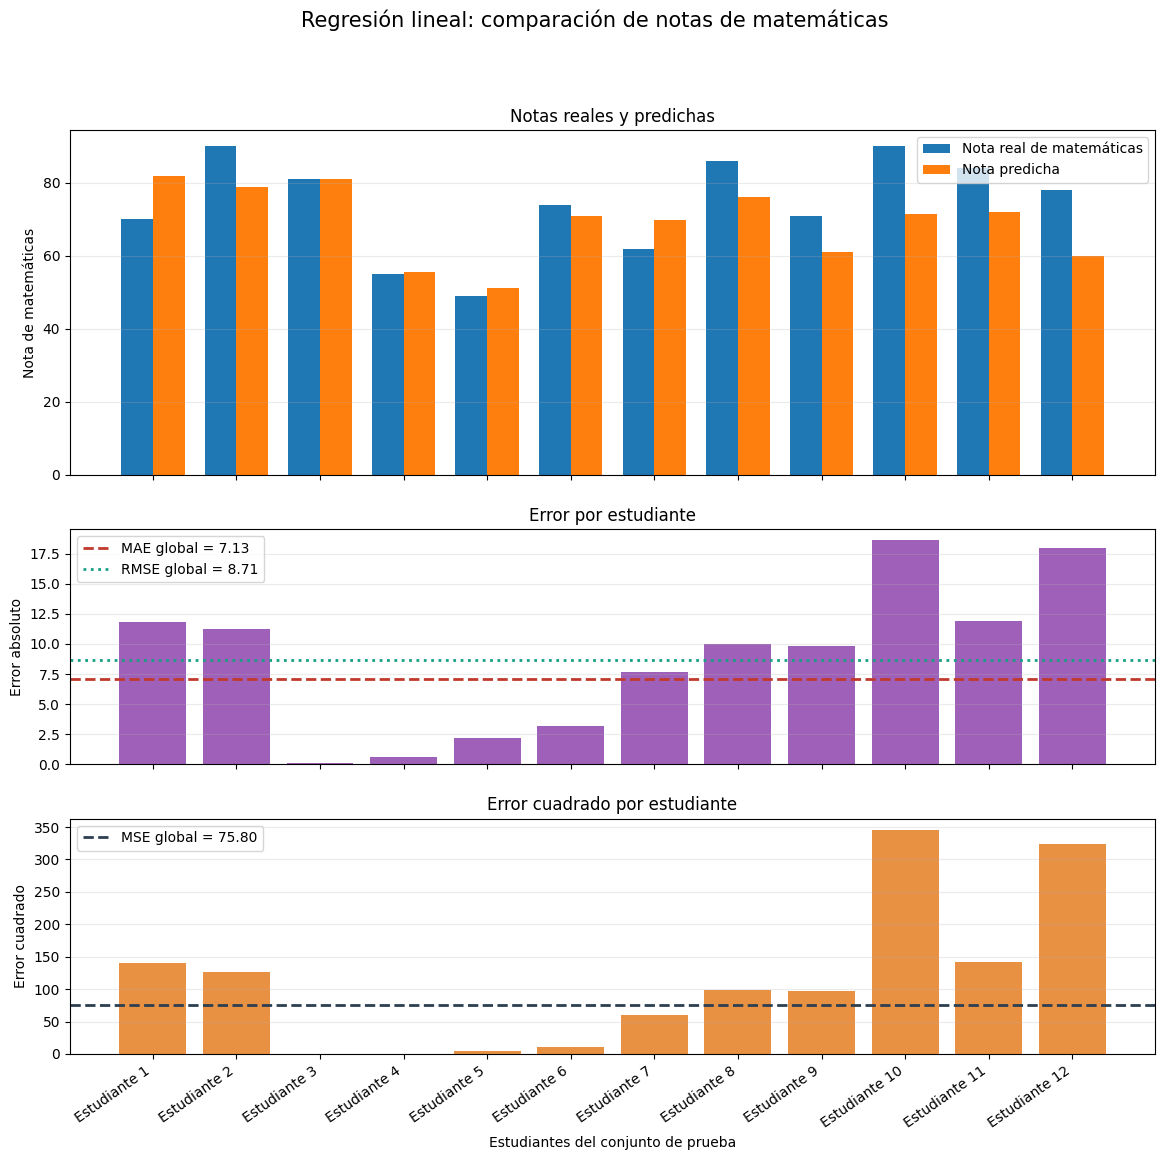

Estudiantes mostrados: 12 de 6129
Métricas globales - MAE: 7.13; RMSE: 8.71; MSE: 75.80
Métricas de la selección - MAE: 8.77; RMSE: 10.60; MSE: 112.30


In [9]:

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Obtener las notas reales y las predicciones
y_test_array = y_test.to_numpy()
predicciones_array = np.asarray(predicciones)

# Seleccionar hasta 12 estudiantes del conjunto de prueba
seleccion = np.arange(min(12, len(y_test_array)))

y_real = y_test_array[seleccion]
y_predicha = predicciones_array[seleccion]

# Calcular los errores de las predicciones
errores = y_real - y_predicha
error_absoluto = np.abs(errores)
error_cuadrado = errores ** 2

# Crear etiquetas para identificar a cada estudiante
etiquetas = [f"Estudiante {i + 1}" for i in seleccion]

# Calcular las métricas globales del modelo
mae_global = mean_absolute_error(y_test_array, predicciones_array)
mse_global = mean_squared_error(y_test_array, predicciones_array)
rmse_global = np.sqrt(mse_global)

# Calcular las métricas de los 12 estudiantes seleccionados
mae_seleccion = error_absoluto.mean()
mse_seleccion = error_cuadrado.mean()
rmse_seleccion = np.sqrt(mse_seleccion)

# Posiciones de las barras
posiciones = np.arange(len(seleccion))
ancho = 0.38

# Crear tres gráficas
fig, (ax_notas, ax_absoluto, ax_cuadrado) = plt.subplots(
    3, 1,
    figsize=(14, 12),
    sharex=True,
    gridspec_kw={"height_ratios": [2.2, 1.5, 1.5]}
)

# Gráfica 1: notas reales y notas predichas
ax_notas.bar(
    posiciones - ancho / 2,
    y_real,
    ancho,
    label="Nota real de matemáticas"
)

ax_notas.bar(
    posiciones + ancho / 2,
    y_predicha,
    ancho,
    label="Nota predicha"
)

ax_notas.set_ylabel("Nota de matemáticas")
ax_notas.set_title("Notas reales y predichas")
ax_notas.legend()
ax_notas.grid(axis="y", alpha=0.25)

# Gráfica 2: errores absolutos
ax_absoluto.bar(
    posiciones,
    error_absoluto,
    color="#8e44ad",
    alpha=0.85
)

ax_absoluto.axhline(
    mae_global,
    color="#c0392b",
    linestyle="--",
    linewidth=2,
    label=f"MAE global = {mae_global:.2f}"
)

ax_absoluto.axhline(
    rmse_global,
    color="#16a085",
    linestyle=":",
    linewidth=2,
    label=f"RMSE global = {rmse_global:.2f}"
)

ax_absoluto.set_ylabel("Error absoluto")
ax_absoluto.set_title("Error por estudiante")
ax_absoluto.legend()
ax_absoluto.grid(axis="y", alpha=0.25)

# Gráfica 3: errores cuadrados
ax_cuadrado.bar(
    posiciones,
    error_cuadrado,
    color="#e67e22",
    alpha=0.85
)

ax_cuadrado.axhline(
    mse_global,
    color="#2c3e50",
    linestyle="--",
    linewidth=2,
    label=f"MSE global = {mse_global:.2f}"
)

ax_cuadrado.set_ylabel("Error cuadrado")
ax_cuadrado.set_title("Error cuadrado por estudiante")
ax_cuadrado.legend()
ax_cuadrado.grid(axis="y", alpha=0.25)

# Configurar las etiquetas del eje horizontal
ax_cuadrado.set_xticks(posiciones)
ax_cuadrado.set_xticklabels(etiquetas, rotation=35, ha="right")
ax_cuadrado.set_xlabel("Estudiantes del conjunto de prueba")

# Ajustar y mostrar la figura
fig.suptitle(
    "Regresión lineal: comparación de notas de matemáticas",
    fontsize=15
)

display(fig)
plt.close(fig)

# Mostrar las métricas calculadas
print(f"Estudiantes mostrados: {len(seleccion)} de {len(y_test_array)}")
print(
    f"Métricas globales - MAE: {mae_global:.2f}; "
    f"RMSE: {rmse_global:.2f}; MSE: {mse_global:.2f}"
)
print(
    f"Métricas de la selección - MAE: {mae_seleccion:.2f}; "
    f"RMSE: {rmse_seleccion:.2f}; MSE: {mse_seleccion:.2f}"
)


Filas del dataset: 30641
Filas duplicadas exactas: 0

Valores faltantes por columna:
Sin valores faltantes


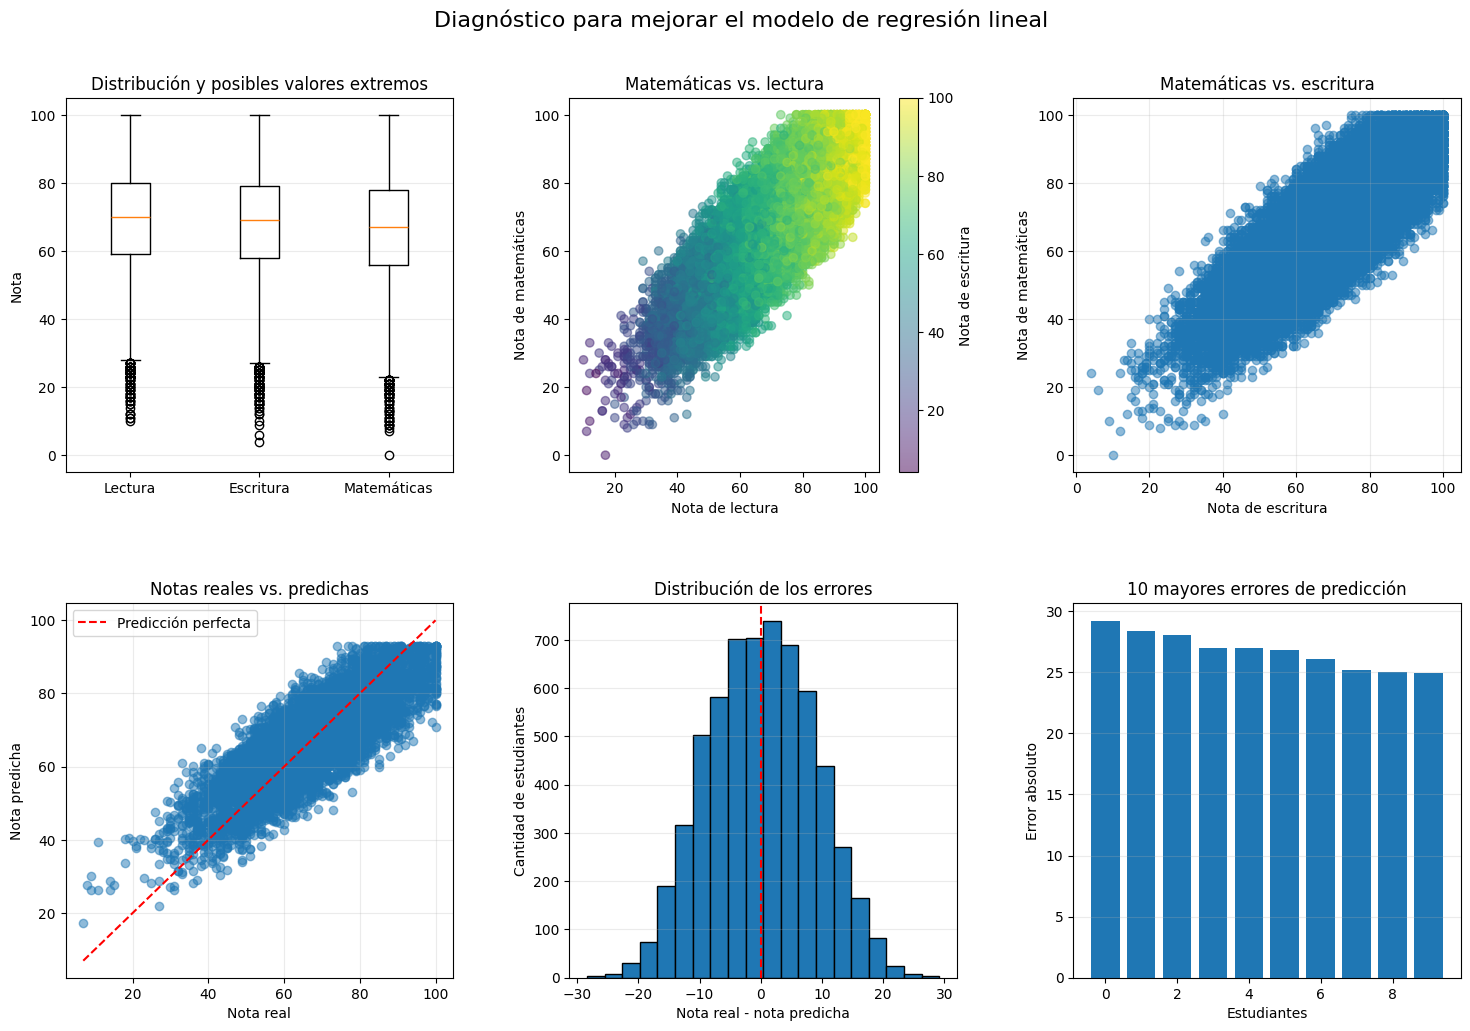


Mayores errores absolutos del conjunto de prueba:


,ReadingScore,WritingScore,Nota real,Nota predicha,Error absoluto
18389,73,76,100,70.81,29.19
28544,39,34,11,39.39,28.39
16095,63,62,33,61.08,28.08
29714,69,64,38,64.99,26.99
2280,70,69,94,67.05,26.95



Valores únicos por columna:
ReadingScore: 90 valores diferentes
WritingScore: 93 valores diferentes
MathScore: 95 valores diferentes


In [10]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# 1. Revisar los datos disponibles
columnas_requeridas = [
    "ReadingScore",
    "WritingScore",
    "MathScore"
]

columnas_disponibles = [
    columna for columna in columnas_requeridas
    if columna in df.columns
]

filas_duplicadas = int(df.duplicated().sum())
valores_faltantes = df[columnas_disponibles].isna().sum()

print(f"Filas del dataset: {len(df)}")
print(f"Filas duplicadas exactas: {filas_duplicadas}")
print("\nValores faltantes por columna:")

print(
    valores_faltantes[valores_faltantes > 0]
    if valores_faltantes.any()
    else "Sin valores faltantes"
)

# 2. Preparar los resultados del conjunto de prueba
prueba = X_test.copy()

prueba["Nota real"] = y_test.to_numpy()
prueba["Nota predicha"] = np.asarray(predicciones)

prueba["Error absoluto"] = np.abs(
    prueba["Nota real"] - prueba["Nota predicha"]
)

prueba["Error cuadrado"] = (
    prueba["Nota real"] - prueba["Nota predicha"]
) ** 2

# 3. Crear las gráficas de diagnóstico
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

# Gráfica 1: distribución de las notas
axes[0, 0].boxplot(
    [
        df["ReadingScore"].dropna(),
        df["WritingScore"].dropna(),
        df["MathScore"].dropna()
    ],
    tick_labels=["Lectura", "Escritura", "Matemáticas"],
    showfliers=True
)

axes[0, 0].set_title("Distribución y posibles valores extremos")
axes[0, 0].set_ylabel("Nota")
axes[0, 0].grid(axis="y", alpha=0.25)

# Gráfica 2: relación entre lectura y matemáticas
scatter = axes[0, 1].scatter(
    df["ReadingScore"],
    df["MathScore"],
    c=df["WritingScore"],
    cmap="viridis",
    alpha=0.5
)

axes[0, 1].set_title("Matemáticas vs. lectura")
axes[0, 1].set_xlabel("Nota de lectura")
axes[0, 1].set_ylabel("Nota de matemáticas")

fig.colorbar(
    scatter,
    ax=axes[0, 1],
    label="Nota de escritura"
)

# Gráfica 3: relación entre escritura y matemáticas
axes[0, 2].scatter(
    df["WritingScore"],
    df["MathScore"],
    alpha=0.5
)

axes[0, 2].set_title("Matemáticas vs. escritura")
axes[0, 2].set_xlabel("Nota de escritura")
axes[0, 2].set_ylabel("Nota de matemáticas")
axes[0, 2].grid(alpha=0.25)

# Gráfica 4: notas reales frente a predichas
axes[1, 0].scatter(
    prueba["Nota real"],
    prueba["Nota predicha"],
    alpha=0.5
)

# Línea de referencia de predicción perfecta
limite_min = min(
    prueba["Nota real"].min(),
    prueba["Nota predicha"].min()
)

limite_max = max(
    prueba["Nota real"].max(),
    prueba["Nota predicha"].max()
)

axes[1, 0].plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    "r--",
    label="Predicción perfecta"
)

axes[1, 0].set_title("Notas reales vs. predichas")
axes[1, 0].set_xlabel("Nota real")
axes[1, 0].set_ylabel("Nota predicha")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.25)

# Gráfica 5: distribución de los errores
axes[1, 1].hist(
    prueba["Nota real"] - prueba["Nota predicha"],
    bins=20,
    edgecolor="black"
)

axes[1, 1].axvline(0, color="red", linestyle="--")
axes[1, 1].set_title("Distribución de los errores")
axes[1, 1].set_xlabel("Nota real - nota predicha")
axes[1, 1].set_ylabel("Cantidad de estudiantes")
axes[1, 1].grid(axis="y", alpha=0.25)

# Gráfica 6: estudiantes con mayores errores
prueba_ordenada = prueba.sort_values(
    "Error absoluto",
    ascending=False
)

mayores_errores = prueba_ordenada.head(10)

axes[1, 2].bar(
    range(len(mayores_errores)),
    mayores_errores["Error absoluto"]
)

axes[1, 2].set_title("10 mayores errores de predicción")
axes[1, 2].set_xlabel("Estudiantes")
axes[1, 2].set_ylabel("Error absoluto")
axes[1, 2].grid(axis="y", alpha=0.25)

fig.suptitle(
    "Diagnóstico para mejorar el modelo de regresión lineal",
    fontsize=16
)

# Mostrar la figura sin utilizar tight_layout
fig.subplots_adjust(
    hspace=0.35,
    wspace=0.3,
    top=0.90,
    bottom=0.10
)

display(fig)
plt.close(fig)

# 4. Mostrar los estudiantes con mayores errores
print("\nMayores errores absolutos del conjunto de prueba:")

display(
    prueba_ordenada[
        [
            "ReadingScore",
            "WritingScore",
            "Nota real",
            "Nota predicha",
            "Error absoluto"
        ]
    ].head(5).round(2)
)

# 5. Revisar los rangos y las categorías de las notas
print("\nValores únicos por columna:")

for columna in columnas_disponibles:
    print(
        f"{columna}: "
        f"{df[columna].nunique()} valores diferentes"
    )


# Genarar y visualizar reporte

In [11]:
from clases.reportes import Reportes

reportes = Reportes()
texto = reportes.generar_reporte(df)

print(texto)

REPORTE DEL DATAFRAME
Filas: 30641
Columnas: 15
Duplicados: 0

Columnas y tipos:
- Unnamed: 0: int64
- Gender: str
- EthnicGroup: str
- ParentEduc: str
- LunchType: str
- TestPrep: str
- ParentMaritalStatus: str
- PracticeSport: str
- IsFirstChild: str
- NrSiblings: float64
- TransportMeans: str
- WklyStudyHours: str
- MathScore: int64
- ReadingScore: int64
- WritingScore: int64

Valores nulos por columna:
- Unnamed: 0: 0
- Gender: 0
- EthnicGroup: 1840
- ParentEduc: 1845
- LunchType: 0
- TestPrep: 1830
- ParentMaritalStatus: 1190
- PracticeSport: 631
- IsFirstChild: 904
- NrSiblings: 1572
- TransportMeans: 3134
- WklyStudyHours: 955
- MathScore: 0
- ReadingScore: 0
- WritingScore: 0

Estadísticas numéricas:
       Unnamed: 0  NrSiblings  MathScore  ReadingScore  WritingScore
count   30641.000   29069.000  30641.000     30641.000     30641.000
mean      499.557       2.146     66.558        69.378        68.419
std       288.748       1.458     15.362        14.759        15.444
min   

# Imprimir Reportes

In [12]:
reportes.imprimir_reporte(df)

REPORTE DEL DATAFRAME
Filas: 30641
Columnas: 15
Duplicados: 0

Columnas y tipos:
- Unnamed: 0: int64
- Gender: str
- EthnicGroup: str
- ParentEduc: str
- LunchType: str
- TestPrep: str
- ParentMaritalStatus: str
- PracticeSport: str
- IsFirstChild: str
- NrSiblings: float64
- TransportMeans: str
- WklyStudyHours: str
- MathScore: int64
- ReadingScore: int64
- WritingScore: int64

Valores nulos por columna:
- Unnamed: 0: 0
- Gender: 0
- EthnicGroup: 1840
- ParentEduc: 1845
- LunchType: 0
- TestPrep: 1830
- ParentMaritalStatus: 1190
- PracticeSport: 631
- IsFirstChild: 904
- NrSiblings: 1572
- TransportMeans: 3134
- WklyStudyHours: 955
- MathScore: 0
- ReadingScore: 0
- WritingScore: 0

Estadísticas numéricas:
       Unnamed: 0  NrSiblings  MathScore  ReadingScore  WritingScore
count   30641.000   29069.000  30641.000     30641.000     30641.000
mean      499.557       2.146     66.558        69.378        68.419
std       288.748       1.458     15.362        14.759        15.444
min   

In [13]:
# Guardar reporte en un txt

ruta = reportes.guardar_reporte(
    df,
    "reportes/student-score-dataset.txt",
)

print(f"Reporte guardado en: {ruta}")

Reporte guardado en: reportes/student-score-dataset.txt


# Conclusion de los resultados esperados



Se construyó y entrenó un modelo de regresión lineal múltiple para predecir las notas de matemáticas utilizando las notas de lectura y escritura. El conjunto de datos se dividió en un 80 % para entrenamiento y un 20 % para prueba, utilizando una semilla aleatoria de 42.

El modelo obtuvo un MAE de 7.13, un RMSE de 8.71 y un R² de 0.67. Estos resultados indican que el modelo logra explicar aproximadamente el 67 % de la variabilidad de las notas de matemáticas en los datos de prueba, aunque sus predicciones presentan errores.

Los coeficientes obtenidos muestran una asociación positiva entre las notas de lectura y escritura y la nota predicha de matemáticas. Sin embargo, el modelo tiene limitaciones porque solo considera dos variables y supone una relación lineal. Por esta razón, se podrían evaluar otros modelos y variables adicionales para intentar mejorar la precisión de las predicciones.